<a href="https://colab.research.google.com/github/julianoliveira600/ProjetoFinal/blob/master/TensorflowKerasFolhasdevideirateste.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
url = '/content/drive/MyDrive/TensorFlow-Keras-classificando-imagens-com-redes-convolucionais/imagens'

In [ ]:
import pathlib

In [ ]:
data_dir = pathlib.Path(url)


In [ ]:
len(list(data_dir.glob('*/*JPG*')))

1600

In [ ]:
subfolders = [f.name for f in data_dir.iterdir() if f.is_dir]

In [ ]:
subfolders

['HealthyGrapes', 'BlackMeasles', 'BlackRot', 'LeafBlight']

In [ ]:
import PIL

In [ ]:
leafblight = list(data_dir.glob('LeafBlight/*'))

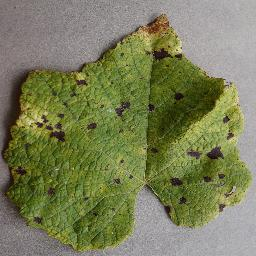

In [ ]:
PIL.Image.open(str(leafblight[0]))

In [ ]:
import numpy as np

In [ ]:
for subfolder in subfolders:
  path = data_dir /subfolder
  images = list(path.glob('*.JPG'))
  print(f'Classe {subfolder} tem {len(images)} imagens')

Classe HealthyGrapes tem 400 imagens
Classe BlackMeasles tem 400 imagens
Classe BlackRot tem 400 imagens
Classe LeafBlight tem 400 imagens


In [ ]:
for subfolder in subfolders:
  path = data_dir / subfolder
  images = list(path.glob('*JPG'))
  print(f'Classe {subfolder} tem {len(images)} imagens')

  if images:
    img = PIL.Image.open(str(images[0]))
    img_array = np.array(img)
    print(f'Dimensões da primeira imagem em {subfolder}: {img_array.shape}')

Classe HealthyGrapes tem 400 imagens
Dimensões da primeira imagem em HealthyGrapes: (256, 256, 3)
Classe BlackMeasles tem 400 imagens
Dimensões da primeira imagem em BlackMeasles: (256, 256, 3)
Classe BlackRot tem 400 imagens
Dimensões da primeira imagem em BlackRot: (256, 256, 3)
Classe LeafBlight tem 400 imagens
Dimensões da primeira imagem em LeafBlight: (256, 256, 3)


In [ ]:
import tensorflow as tf

In [ ]:
batch_size = 64
altura  = 256
largura = 256

In [ ]:
treino = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split = 0.2,
    subset = 'training',
    seed = 568,
    image_size = (altura, largura),
    batch_size=batch_size
)

Found 1600 files belonging to 4 classes.
Using 1280 files for training.


In [ ]:
validacao = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split = 0.2,
    subset = 'validation',
    seed = 568,
    image_size = (altura, largura),
    batch_size=batch_size
)

Found 1600 files belonging to 4 classes.
Using 320 files for validation.


In [ ]:
treino.class_names

['BlackMeasles', 'BlackRot', 'HealthyGrapes', 'LeafBlight']

In [ ]:
tf.random.set_seed(424242)

In [ ]:
modelo = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(256,256,3)),
  tf.keras.layers.Rescaling(1./255),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation=tf.nn.relu),
  tf.keras.layers.Dense(4, activation=tf.nn.softmax)
])

In [ ]:
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found  GPU at: {}'.format(device_name))

Found  GPU at: /device:GPU:0


In [ ]:
epocas = 10

history = modelo.fit(
    treino,
    validation_data=validacao,
    epochs=epocas
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 256s 13s/step - accuracy: 0.2341 - loss: 103.2650 - val_accuracy: 0.4563 - val_loss: 9.6996
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 189ms/step - accuracy: 0.3737 - loss: 4.8716 - val_accuracy: 0.5250 - val_loss: 1.8028
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 188ms/step - accuracy: 0.5275 - loss: 1.7832 - val_accuracy: 0.5594 - val_loss: 1.3733
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 245ms/step - accuracy: 0.5888 - loss: 1.2361 - val_accuracy: 0.6969 - val_loss: 0.8233
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 193ms/step - accuracy: 0.6724 - loss: 0.8545 - val_accuracy: 0.6656 - val_loss: 0.8385
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.7116 - loss: 0.6601 - val_accuracy: 0.6969 - val_loss: 0.6441
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 245ms/step - accuracy: 0.7446 - loss: 0.6185 - val_accuracy: 0.6125 - val_loss: 1.0712
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 201ms/step - accuracy: 0.7100 - loss: 0.7581 - val_accuracy: 

In [ ]:
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 196608)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    25,165,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,499,406 (288.01 MB)

 Trainable params: 25,166,468 (96.00 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 50,332,938 (192.00 MB)

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
def plota_resultados(history, epocas):
  acc = history.history['accuracy']
  val_acc = history.history['val_accuracy']

  loss = history.history['loss']
  val_loss = history.history['val_loss']

  intervalo_epocas = range(epocas)

  plt.figure(figsize=(12,6))
  plt.subplot(1,2,1)
  plt.plot(intervalo_epocas, acc, 'r', label='Acurácia do Treino')
  plt.plot(intervalo_epocas, val_acc, 'b', label='Acurácia de validação')
  plt.legend(loc= 'lower right')

  plt.subplot(1,2,2)

  plt.plot(intervalo_epocas, loss, 'r', label='Perda do Treino')
  plt.plot(intervalo_epocas, val_loss, 'b', label='Perda da Validação')
  plt.legend(loc='upper right')
  plt.show()

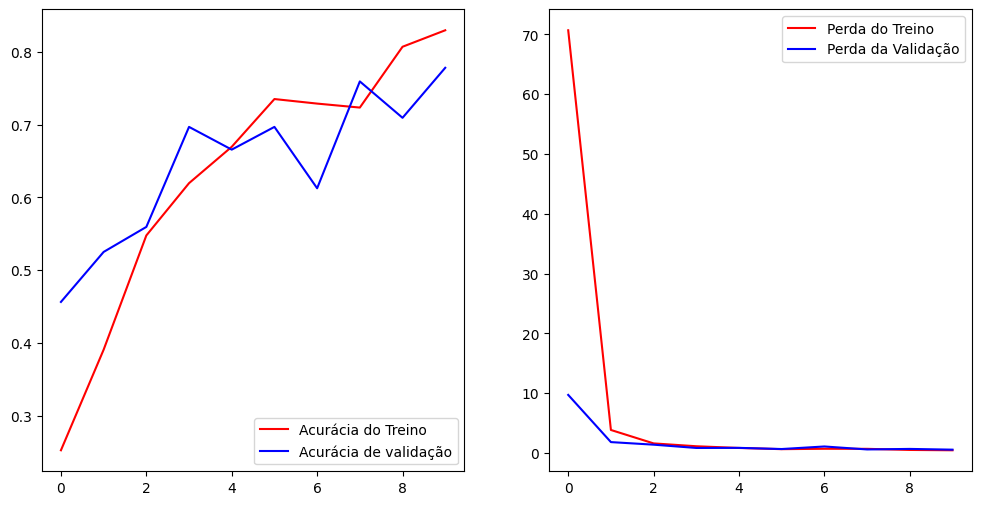

In [ ]:
plota_resultados(history, epocas)

In [ ]:
modelo = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(256,256,3)),
  tf.keras.layers.Rescaling(1./255),
  tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
  tf.keras.layers.MaxPooling2D(2,2),
  tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
  tf.keras.layers.MaxPooling2D(2,2),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation=tf.nn.relu),
  tf.keras.layers.Dense(4, activation=tf.nn.softmax)
])

In [ ]:
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
epocas = 10

history = modelo.fit(
    treino,
    validation_data=validacao,
    epochs=epocas
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 305ms/step - accuracy: 0.3587 - loss: 2.9082 - val_accuracy: 0.7688 - val_loss: 0.5854
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 225ms/step - accuracy: 0.7888 - loss: 0.5055 - val_accuracy: 0.8813 - val_loss: 0.3586
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 248ms/step - accuracy: 0.9181 - loss: 0.2466 - val_accuracy: 0.8906 - val_loss: 0.3313
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 263ms/step - accuracy: 0.9418 - loss: 0.1595 - val_accuracy: 0.9281 - val_loss: 0.2083
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 215ms/step - accuracy: 0.9819 - loss: 0.0582 - val_accuracy: 0.9281 - val_loss: 0.2272
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 243ms/step - accuracy: 0.9777 - loss: 0.0739 - val_accuracy: 0.9250 - val_loss: 0.2367
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 204ms/step - accuracy: 0.9953 - loss: 0.0277 - val_accuracy: 0.9344 - val_loss: 0.1844
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 211ms/step - accuracy: 0.9968 - loss: 0.0243 - val_accuracy: 0

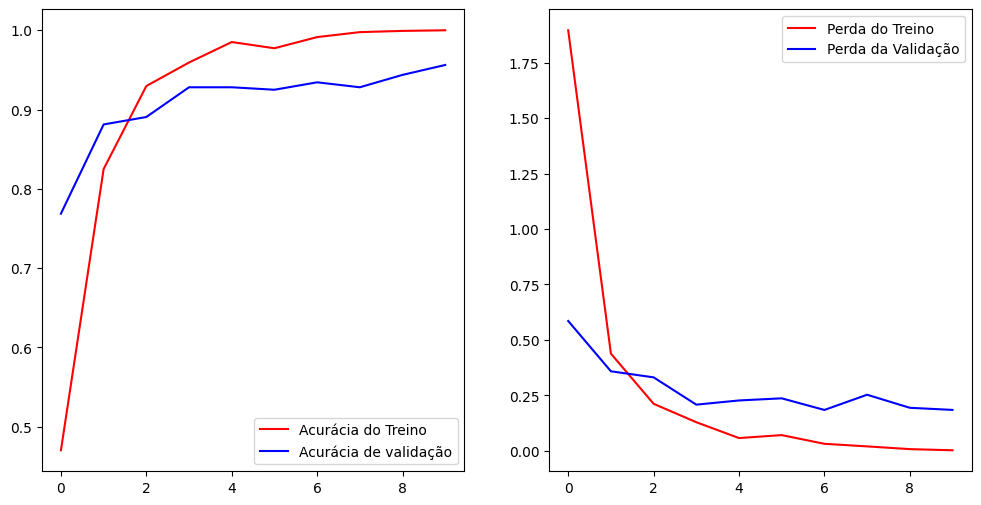

In [ ]:
plota_resultados(history, epocas)

In [ ]:
modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 123008)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    15,745,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,267,438 (180.31 MB)

 Trainable params: 15,755,812 (60.10 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 31,511,626 (120.21 MB)

In [ ]:
class myCallback(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs={}):
    if(logs.get ('accuracy')>=0.93):
      print('\n Alcançamos 93% de acurácia. Parando o treinamento')
      self.model.stop_training = True

callbacks = myCallback()

In [ ]:
modelo = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(256,256,3)),
  tf.keras.layers.Rescaling(1./255),
  tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
  tf.keras.layers.MaxPooling2D(2,2),
  tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
  tf.keras.layers.MaxPooling2D(2,2),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation=tf.nn.relu),
  tf.keras.layers.Dense(4, activation=tf.nn.softmax)
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
epocas = 50

history = modelo.fit(
    treino,
    validation_data=validacao,
    epochs=epocas
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 254ms/step - accuracy: 0.2815 - loss: 3.8077 - val_accuracy: 0.4688 - val_loss: 1.0397
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 198ms/step - accuracy: 0.6057 - loss: 0.8811 - val_accuracy: 0.7531 - val_loss: 0.5375
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 208ms/step - accuracy: 0.8461 - loss: 0.3914 - val_accuracy: 0.9094 - val_loss: 0.2697
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 259ms/step - accuracy: 0.9243 - loss: 0.2035 - val_accuracy: 0.9438 - val_loss: 0.1779
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 212ms/step - accuracy: 0.9756 - loss: 0.0898 - val_accuracy: 0.9438 - val_loss: 0.1820
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 210ms/step - accuracy: 0.9841 - loss: 0.0652 - val_accuracy: 0.9469 - val_loss: 0.1653
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 257ms/step - accuracy: 0.9910 - loss: 0.0422 - val_accuracy: 0.9500 - val_loss: 0.1566
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 206ms/step - accuracy: 0.9973 - loss: 0.0247 - val_accuracy: 0.

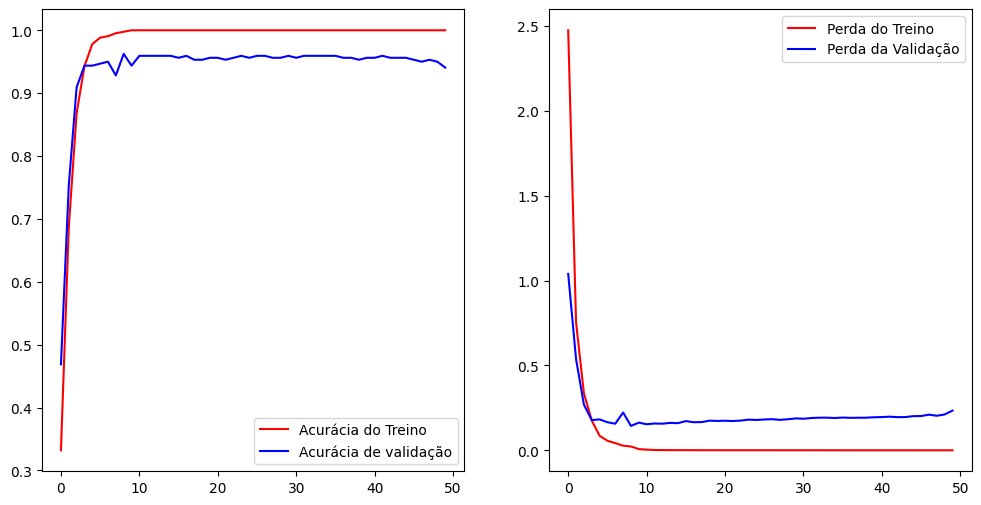

In [ ]:
plota_resultados(history, epocas)

In [ ]:
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.05),
  tf.keras.layers.RandomZoom(0.05)
])

In [ ]:
modelo = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(256,256,3)),

  # data_augmentation,
  data_augmentation,
  tf.keras.layers.Rescaling(1./255),
  # Add convolutions and max pooling
  tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
  tf.keras.layers.MaxPooling2D(2,2),
  tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
  tf.keras.layers.MaxPooling2D(2,2),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation=tf.nn.relu),
  tf.keras.layers.Dense(4, activation=tf.nn.softmax)
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
epocas = 50

history = modelo.fit(
    treino,
    validation_data=validacao,
    epochs=epocas
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 238ms/step - accuracy: 0.2704 - loss: 4.5141 - val_accuracy: 0.2469 - val_loss: 1.3445
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - accuracy: 0.3733 - loss: 1.1754 - val_accuracy: 0.4031 - val_loss: 1.3516
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 243ms/step - accuracy: 0.6786 - loss: 0.8562 - val_accuracy: 0.7656 - val_loss: 0.6610
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 211ms/step - accuracy: 0.8365 - loss: 0.4334 - val_accuracy: 0.6750 - val_loss: 1.1837
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 202ms/step - accuracy: 0.8728 - loss: 0.3622 - val_accuracy: 0.8375 - val_loss: 0.5712
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 233ms/step - accuracy: 0.8864 - loss: 0.3099 - val_accuracy: 0.7906 - val_loss: 0.7800
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 221ms/step - accuracy: 0.9015 - loss: 0.2339 - val_accuracy: 0.7312 - val_loss: 1.2220
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step - accuracy: 0.9188 - loss: 0.2082 - val_accuracy: 0

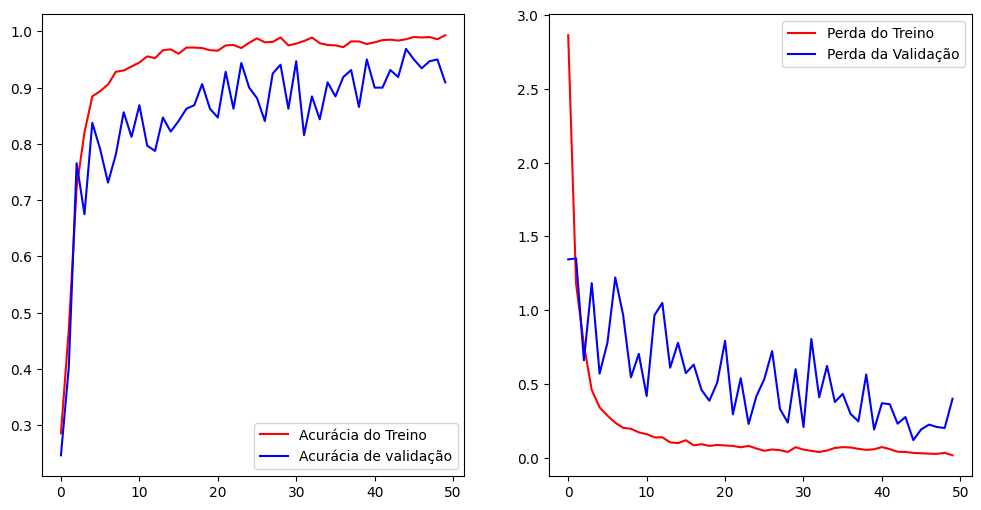

In [ ]:
plota_resultados(history, epocas)

In [ ]:
modelo.save('modelo_apos_aumento.h5')

In [ ]:
input_shape = (256,256,3)

In [ ]:
modelo_base = tf.keras.applications.InceptionV3(input_shape=input_shape, include_top=False, weights='imagenet')

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
modelo_base.trainable = False

In [ ]:
modelo_base.summary()

Model: "inception_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 127, 127,  │        864 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 127, 127,  │         96 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 127, 127,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 125, 125,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 125, 125,  │         96 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 125, 125,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 125, 125,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 125, 125,  │        192 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 125, 125,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 62, 62,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 62, 62,    │      5,120 │ max_pooling2d_6[… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 62, 62,    │        240 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 62, 62,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 60, 60,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 60, 60,    │        576 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 60, 60,    │          0 │ batch_normalizat

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
rescale = tf.keras.layers.Rescaling((1./255))
treino = treino.map(lambda x, y: (rescale(x), y))
validacao = validacao.map(lambda x, y: (rescale(x), y))

In [ ]:
ultima_camada = modelo_base.get_layer('mixed7')
print('ultima_camada', ultima_camada.output.shape)
ultima_saida = ultima_camada.output

ultima_camada (None, 14, 14, 768)


In [ ]:
x = tf.keras.layers.Flatten()(ultima_saida)
x = tf.keras.layers.Dense(1024, activation='relu')(x)
x = tf.keras.layers.Dense(4, activation = 'softmax')(x)
x = tf.keras.layers.Dropout(0.2)(x)
x = tf.keras.layers.Dense(4, activation='softmax')(x)

modelo = tf.keras.Model(inputs=modelo_base.input, outputs=x)

In [ ]:
modelo.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 127, 127,  │        864 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 127, 127,  │         96 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 127, 127,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 125, 125,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 125, 125,  │         96 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 125, 125,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 125, 125,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 125, 125,  │        192 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 125, 125,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 62, 62,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 62, 62,    │      5,120 │ max_pooling2d_6[… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 62, 62,    │        240 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 62, 62,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 60, 60,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 60, 60,    │        576 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 60, 60,    │          0 │ batch_normalizat

 Total params: 163,121,080 (622.26 MB)

 Trainable params: 154,145,816 (588.02 MB)

 Non-trainable params: 8,975,264 (34.24 MB)

In [ ]:
modelo.compile(optimizer= tf.keras.optimizers.Adam(),
                loss = 'sparse_categorical_crossentropy',
               metrics=['accuracy'])

In [ ]:
epocas = 20

history = modelo.fit(
    treino,
    validation_data=validacao,
    epochs=epocas
)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 531ms/step - accuracy: 0.3650 - loss: 1.3556 - val_accuracy: 0.5469 - val_loss: 1.2495
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 255ms/step - accuracy: 0.4620 - loss: 1.3245 - val_accuracy: 0.4938 - val_loss: 1.2530
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 250ms/step - accuracy: 0.4393 - loss: 1.2577 - val_accuracy: 0.5437 - val_loss: 1.2268
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 274ms/step - accuracy: 0.5339 - loss: 1.2018 - val_accuracy: 0.5562 - val_loss: 1.2193
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 236ms/step - accuracy: 0.5358 - loss: 1.2050 - val_accuracy: 0.5156 - val_loss: 1.3134
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 281ms/step - accuracy: 0.5431 - loss: 1.2061 - val_accuracy: 0.6594 - val_loss: 1.1254
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 233ms/step - accuracy: 0.5610 - loss: 1.1459 - val_accuracy: 0.5781 - val_loss: 1.1570
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 243ms/step - accuracy: 0.5487 - loss: 1.1373 - val_accuracy: 0

In [ ]:
modelo.save('modelo_transferencia_de_aprendizado.h5')

In [ ]:
modelo.save('modelo_final_transferencia_de_aprendizado.h5', include_optimizer=False)

In [ ]:
# Correto
modelo.save_weights('pesos.weights.h5')

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(modelo)

In [ ]:
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]

In [ ]:
modelo_tflite_quantizado = converter.convert()

Saved artifact at '/tmp/tmp2j3w7_1w'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor_37')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136299915082064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915070736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915080912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915071504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915081296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915071120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915081104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915080528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915079568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136299915067664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13629991506

In [ ]:

with open('modelo_quantizado16bits.tflite', 'wb') as f:
  f.write(modelo_tflite_quantizado)